In [2]:
# загрузка данных 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('HR.csv')

df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [3]:
# расчет статистических данных
numeric_columns = df.select_dtypes(include=np.number).columns

statistics = pd.DataFrame({
    'Среднее': df[numeric_columns].mean(),
    'Медиана': df[numeric_columns].median(),
    'Мода': df[numeric_columns].mode().iloc[0],
    'Минимум': df[numeric_columns].min(),
    'Максимум': df[numeric_columns].max(),
    'Стандартное отклонение': df[numeric_columns].std()
})

statistics

,Среднее,Медиана,Мода,Минимум,Максимум,Стандартное отклонение
satisfaction_level,0.612834,0.64,0.10,0.09,1.0,0.248631
last_evaluation,0.716102,0.72,0.55,0.36,1.0,0.171169
number_project,3.803054,4.00,4.00,2.00,7.0,1.232592
average_montly_hours,201.050337,200.00,135.00,96.00,310.0,49.943099
time_spend_company,3.498233,3.00,3.00,2.00,10.0,1.460136
Work_accident,0.144610,0.00,0.00,0.00,1.0,0.351719
left,0.238083,0.00,0.00,0.00,1.0,0.425924
promotion_last_5years,0.021268,0.00,0.00,0.00,1.0,0.144281


In [4]:
# корреляционная матрица
correlation_matrix = df[numeric_columns].corr()

correlation_matrix

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
satisfaction_level,1.000000,0.105021,-0.142970,-0.020048,-0.100866,0.058697,-0.388375,0.025605
last_evaluation,0.105021,1.000000,0.349333,0.339742,0.131591,-0.007104,0.006567,-0.008684
number_project,-0.142970,0.349333,1.000000,0.417211,0.196786,-0.004741,0.023787,-0.006064
average_montly_hours,-0.020048,0.339742,0.417211,1.000000,0.127755,-0.010143,0.071287,-0.003544
time_spend_company,-0.100866,0.131591,0.196786,0.127755,1.000000,0.002120,0.144822,0.067433
Work_accident,0.058697,-0.007104,-0.004741,-0.010143,0.002120,1.000000,-0.154622,0.039245
left,-0.388375,0.006567,0.023787,0.071287,0.144822,-0.154622,1.000000,-0.061788
promotion_last_5years,0.025605,-0.008684,-0.006064,-0.003544,0.067433,0.039245,-0.061788,1.000000


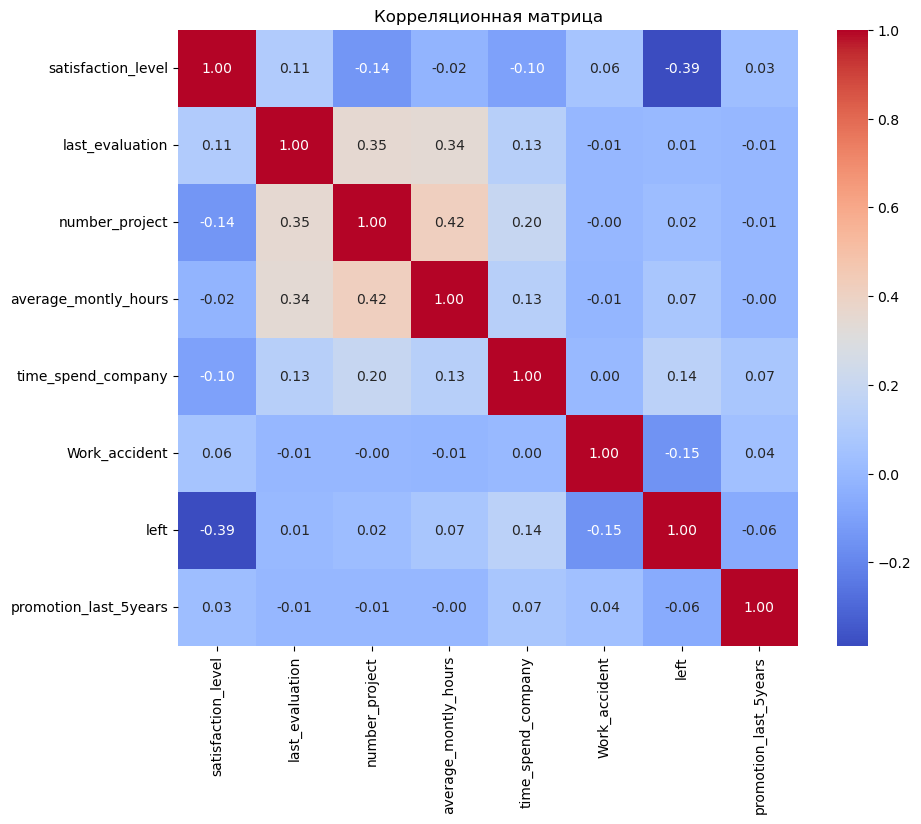

In [5]:
# визуализация полученной матрицы 
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Корреляционная матрица')
plt.show()

In [6]:
# наиболее и наименее скоррелированные матрицы
corr_pairs = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

corr_pairs = corr_pairs.stack().sort_values()

corr_pairs

satisfaction_level    left                    -0.388375
Work_accident         left                    -0.154622
satisfaction_level    number_project          -0.142970
                      time_spend_company      -0.100866
left                  promotion_last_5years   -0.061788
satisfaction_level    average_montly_hours    -0.020048
average_montly_hours  Work_accident           -0.010143
last_evaluation       promotion_last_5years   -0.008684
                      Work_accident           -0.007104
number_project        promotion_last_5years   -0.006064
                      Work_accident           -0.004741
average_montly_hours  promotion_last_5years   -0.003544
time_spend_company    Work_accident            0.002120
last_evaluation       left                     0.006567
number_project        left                     0.023787
satisfaction_level    promotion_last_5years    0.025605
Work_accident         promotion_last_5years    0.039245
satisfaction_level    Work_accident            0

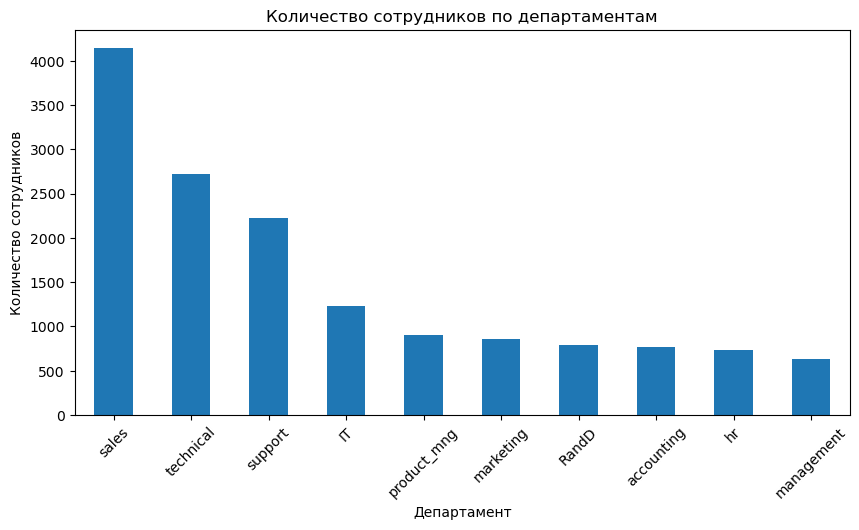

In [7]:
# количество сотрудников в каждом департаменте
department_counts = df['department'].value_counts()

department_counts

department_counts.plot(kind='bar', figsize=(10, 5))

plt.title('Количество сотрудников по департаментам')
plt.xlabel('Департамент')
plt.ylabel('Количество сотрудников')
plt.xticks(rotation=45)
plt.show()


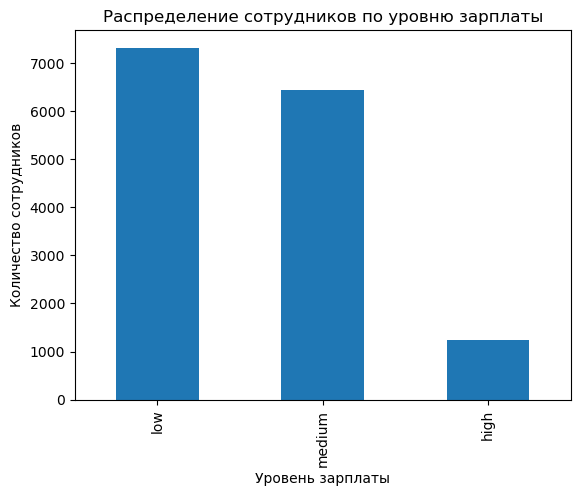

In [11]:
# распределение сотрудников по зарплатам
salary_counts = df['salary'].value_counts()

salary_counts

salary_counts.plot(kind='bar')

plt.title('Распределение сотрудников по уровню зарплаты')
plt.xlabel('Уровень зарплаты')
plt.ylabel('Количество сотрудников')
plt.show()

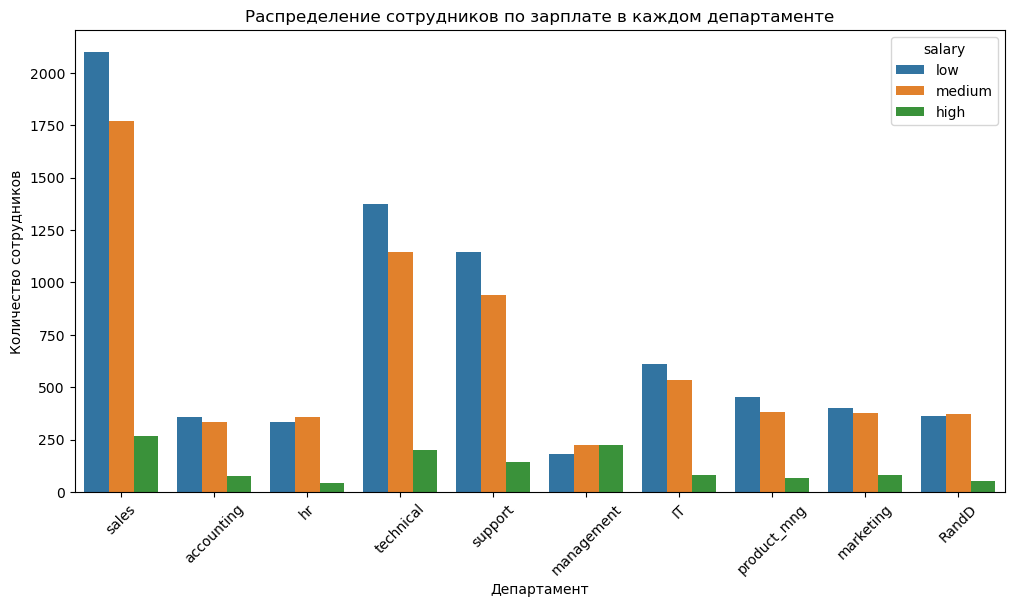

salary,high,low,medium
department,,,
IT,83,609,535
RandD,51,364,372
accounting,74,358,335
hr,45,335,359
management,225,180,225
marketing,80,402,376
product_mng,68,451,383
sales,269,2099,1772
support,141,1146,942


In [8]:
# зп в каждом департаменте
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='department',
    hue='salary'
)

plt.title('Распределение сотрудников по зарплате в каждом департаменте')
plt.xlabel('Департамент')
plt.ylabel('Количество сотрудников')
plt.xticks(rotation=45)
plt.show()

pd.crosstab(df['department'], df['salary'])

In [9]:
# гипотеза о соотношении зп и времени работы
df.groupby('salary')['average_montly_hours'].mean()


salary
high      199.867421
low       200.996583
medium    201.338349
Name: average_montly_hours, dtype: float64

In [18]:
# t-критерий
from scipy.stats import ttest_ind

low_salary_hours = df[df['salary'] == 'low']['average_montly_hours']
high_salary_hours = df[df['salary'] == 'high']['average_montly_hours']

ttest_ind(
    high_salary_hours,
    low_salary_hours,
    equal_var=False
)

TtestResult(statistic=np.float64(-0.7624331665385475), pvalue=np.float64(0.4459045542257889), df=np.float64(1745.1248036298136))

In [11]:
# показатели среди уволившихся и оставшихся 
# доля получивших повышение
promotion_rate = df.groupby('left')['promotion_last_5years'].mean()

promotion_rate

left
0    0.026251
1    0.005321
Name: promotion_last_5years, dtype: float64

In [12]:
# средняя удовлетворенность 
df.groupby('left')['satisfaction_level'].mean()

# среднее количество проектов
df.groupby('left')['number_project'].mean()

left
0    3.786664
1    3.855503
Name: number_project, dtype: float64

In [13]:
# таблица
comparison = df.groupby('left').agg({
    'promotion_last_5years': 'mean',
    'satisfaction_level': 'mean',
    'number_project': 'mean'
})

comparison

,promotion_last_5years,satisfaction_level,number_project
left,,,
0,0.026251,0.666810,3.786664
1,0.005321,0.440098,3.855503


In [14]:
# обучающая и тестовая выборки
from sklearn.model_selection import train_test_split

X = df[
    [
        'satisfaction_level',
        'last_evaluation',
        'number_project',
        'average_montly_hours',
        'time_spend_company',
        'Work_accident',
        'promotion_last_5years'
    ]
]

y = df['left']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [15]:
# LDA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis()

lda.fit(X_train, y_train)

,solver,'svd'
,shrinkage,None
,priors,None
,n_components,None
,store_covariance,False
,tol,0.0001
,covariance_estimator,None


In [16]:
# прогноз увольнений
y_pred = lda.predict(X_test)

y_pred[:10]

pd.Series(y_pred).value_counts()

0    2636
1     364
Name: count, dtype: int64

In [17]:
# оценка модели
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print('Accuracy:', accuracy)

print(f'Accuracy: {accuracy:.2%}')

Accuracy: 0.7666666666666667
Accuracy: 76.67%


В результате анализа было установлено, что наиболее выраженная положительная корреляция наблюдается между количеством проектов и средним количеством рабочих часов в месяц (r ≈ 0,417), а наиболее выраженная отрицательная — между уровнем удовлетворённости и фактом увольнения (r ≈ −0,388). Наименее скоррелированными оказались стаж работы и наличие несчастного случая (r ≈ 0,002).

Наибольшее количество сотрудников работает в отделе продаж — 4140 человек. Большинство сотрудников имеют низкий или средний уровень заработной платы, тогда как сотрудников с высокой зарплатой значительно меньше.

Проверка гипотезы о том, что высокооплачиваемые сотрудники проводят на работе больше времени, не подтвердила это предположение. Среднее количество рабочих часов составляет около 201 часа у сотрудников с низкой зарплатой и около 199,9 часов у сотрудников с высокой зарплатой. Различия статистически незначимы (p ≈ 0,446).

Уволившиеся сотрудники имеют более низкий средний уровень удовлетворённости работой (0,440 против 0,667 у оставшихся сотрудников), реже получали повышение за последние пять лет и в среднем выполняли немного больше проектов.

Для прогнозирования увольнения была построена модель линейного дискриминантного анализа (LDA), использующая количественные признаки, за исключением department и salary. На тестовой выборке модель показала accuracy около 76,67%, то есть правильно классифицировала примерно 77% сотрудников. 